In [2]:
!pip install pandas tensorflow scikit-learn matplotlib seaborn

In [3]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow import keras
import os
import matplotlib.pyplot as plt

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'  # Suppress TensorFlow logging (1)

In [4]:
fashion_mnist_data  = keras.datasets.fashion_mnist
(all_x_train, all_y_train), (x_test,y_test) = fashion_mnist_data.load_data()

all_x_train = all_x_train.astype(np.float32)
x_test = x_test.astype(np.float32)

In [5]:
print(f"all_x_train shape: {all_x_train.shape}")
print(f"all_x_train[0] shape: {all_x_train[0].shape}")
print(f"all_x_train.dtype: {all_x_train.dtype}")

print(f"x_test shape: {x_test.shape}")

all_x_train shape: (60000, 28, 28)
all_x_train[0] shape: (28, 28)
all_x_train.dtype: float32
x_test shape: (10000, 28, 28)


In [6]:
x_validation, x_train = all_x_train[:5000] / 255.0, all_x_train[5000:] / 255.0
y_validation, y_train = all_y_train[:5000], all_y_train[5000:]

In [7]:
print(f"x_train.shape: {x_train.shape}")
print(f"x_train[0].shape: {x_train[0].shape}")
print(f"x_train.dtype: {x_train.dtype}")

x_train.shape: (55000, 28, 28)
x_train[0].shape: (28, 28)
x_train.dtype: float32


In [8]:
fashion_mnist_class_names = ["T-shirt/top", "Trouser",  "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag",  "Ankle boot"] 

In [9]:
for cls in range(5):
    print(f"Class {cls}: {fashion_mnist_class_names[y_train[cls]]}")

Class 0: Coat
Class 1: T-shirt/top
Class 2: Sneaker
Class 3: Ankle boot
Class 4: Ankle boot


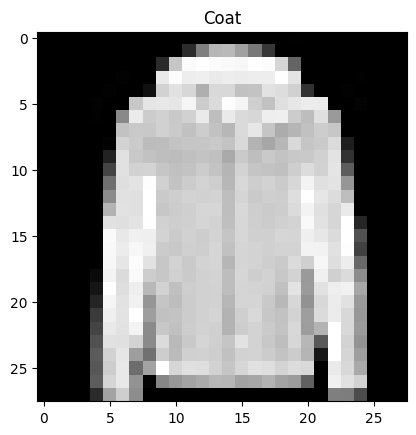

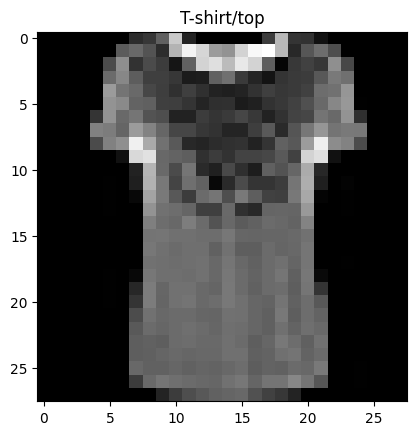

In [10]:
for i in range(2):
    my_img = x_train[i]
    my_img_class = y_train[i]
    my_img_class_name = fashion_mnist_class_names[my_img_class]
    plt.imshow(my_img, cmap='gray')
    plt.title(my_img_class_name)
    plt.show()

## Définir un MLP avec Sequential API

In [11]:
model1 = keras.models.Sequential()
model1.add(keras.layers.Flatten(input_shape=[28, 28]))
model1.add(keras.layers.Dense(300, activation="relu"))
model1.add(keras.layers.Dense(150, activation="relu"))
model1.add(keras.layers.Dense(10, activation="softmax"))

model1.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 300)            │       235,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 150)            │        45,150 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,510 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 282,160 (1.08 MB)

 Trainable params: 282,160 (1.08 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
hidden_ = model1.get_layer('dense_1')

weights, biases = hidden_.get_weights()

print("Les poids : \n", weights)
print(weights.shape)
print("Les biais : \n", biases)
print(biases.shape)

Les poids : 
 [[-0.06947528  0.09307687  0.01607585 ... -0.11527365 -0.08823081
  -0.06685573]
 [ 0.09294063 -0.08729633 -0.10427531 ... -0.048898    0.09021893
  -0.09950297]
 [-0.05034933  0.10473363 -0.02291504 ...  0.01414579 -0.07689305
   0.02519052]
 ...
 [-0.09196699 -0.10189909  0.10284731 ... -0.08812375 -0.04842327
   0.03652149]
 [ 0.02521344 -0.03001767  0.09635489 ...  0.0007513   0.01981044
   0.02350201]
 [ 0.09911904 -0.0033191   0.00680764 ... -0.01799867  0.06118123
  -0.05054521]]
(300, 150)
Les biais : 
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0.]
(150,)


## Initialisation des poids et des biais d'un réseau de neurones

In [13]:
model2 = keras.models.Sequential()
model2.add(keras.layers.Flatten(input_shape=[28, 28]))
model2.add(keras.layers.Dense(300, activation="relu"))

my_weights_initializer = tf.keras.initializers.RandomNormal(mean=100, stddev=1)

my_biais_initializer = tf.keras.initializers.Ones() 

model2.add(keras.layers.Dense(150, activation="relu", 
                              kernel_initializer=my_weights_initializer,
                              bias_initializer=my_biais_initializer))

model2.add(keras.layers.Dense(10, activation="softmax"))

model2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 300)            │       235,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 150)            │        45,150 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,510 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 282,160 (1.08 MB)

 Trainable params: 282,160 (1.08 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
hidden_ = model2.get_layer('dense_4')
weights, biases = hidden_.get_weights()

print("Les poids : \n")
print(weights)
print(weights.shape)
print("Les biais : \n")
print(biases)
print(biases.shape)

Les poids : 

[[100.194534  99.48135   98.86537  ...  99.97038  101.9531   100.152374]
 [101.36092   99.21452   99.961845 ... 101.435905 100.770584 100.314255]
 [101.32538   99.24709   99.55392  ...  98.1427    99.45262   99.405525]
 ...
 [100.46202   99.005    100.29124  ... 100.22252  100.62214   99.023926]
 [101.1176    99.48404   98.64659  ...  99.89334  101.94821   99.3426  ]
 [ 99.50398   98.535545  98.00406  ... 100.41819   98.94024  100.794266]]
(300, 150)
Les biais : 

[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1.]
(150,)


## Compiler un réseau de neurones

In [15]:
model1.compile(loss="sparse_categorical_crossentropy", optimizer="sgd", metrics=["accuracy"])

In [16]:
results = model1.fit(x_train, y_train, epochs=40, validation_data=(x_validation, y_validation))

Epoch 1/40
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.7656 - loss: 0.7211 - val_accuracy: 0.8350 - val_loss: 0.4912
Epoch 2/40
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.8297 - loss: 0.4874 - val_accuracy: 0.8326 - val_loss: 0.4690
Epoch 3/40
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8434 - loss: 0.4428 - val_accuracy: 0.8504 - val_loss: 0.4278
Epoch 4/40
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8543 - loss: 0.4154 - val_accuracy: 0.8546 - val_loss: 0.4290
Epoch 5/40
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8605 - loss: 0.3961 - val_accuracy: 0.8684 - val_loss: 0.3771
Epoch 6/40
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8652 - loss: 0.3800 - val_accuracy: 0.8632 - val_loss: 0.3838
Epoch 7/40
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8690 - loss: 0.3664 - val_accuracy: 0.8754 - val_loss: 0.3568
Epoch 8/40
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8732 - loss: 0.3555 - 

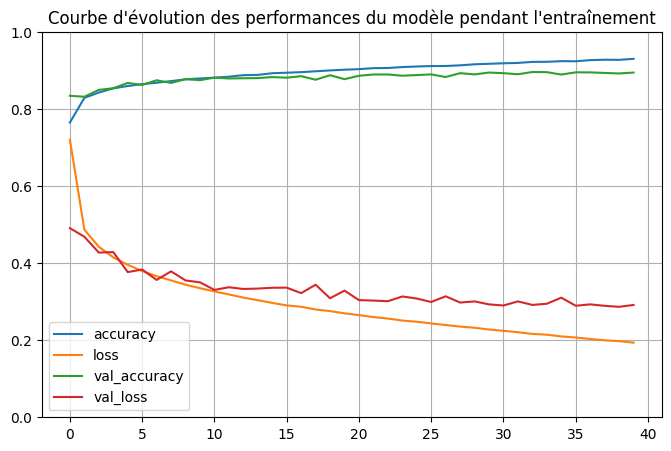

In [17]:
pd.DataFrame(results.history).plot(figsize=(8, 5))
plt.grid(True)
plt.gca().set_ylim(0, 1)
plt.title("Courbe d'évolution des performances du modèle pendant l'entraînement")
plt.show()

In [18]:
x_test = x_test / 255.0
print("Evaluation du modèle sur le jeu de test :")
model1.evaluate(x_test, y_test)

Evaluation du modèle sur le jeu de test :
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8863 - loss: 0.3267


[0.32665184140205383, 0.8863000273704529]

In [21]:
x_new = x_test[0:7]
y_prob = model1.predict(x_new)
print(f"y_prob: \n{y_prob.round(2)}")
y_pred = model1.predict(x_new)
print(f"\ny_pred :\n {y_pred}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
y_prob: 
[[0.   0.   0.   0.   0.   0.   0.   0.01 0.   0.99]
 [0.   0.   1.   0.   0.   0.   0.   0.   0.   0.  ]
 [0.   1.   0.   0.   0.   0.   0.   0.   0.   0.  ]
 [0.   1.   0.   0.   0.   0.   0.   0.   0.   0.  ]
 [0.09 0.   0.   0.   0.   0.   0.9  0.   0.   0.  ]
 [0.   1.   0.   0.   0.   0.   0.   0.   0.   0.  ]
 [0.   0.   0.   0.   0.99 0.   0.   0.   0.   0.  ]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step

y_pred :
 [[2.80709583e-06 6.88726345e-07 2.32474849e-06 4.29791669e-07
  4.32479027e-07 2.10019248e-03 6.85002124e-06 1.12108095e-02
  3.01234559e-05 9.86645401e-01]
 [6.80374360e-05 1.06404174e-09 9.95507598e-01 1.69121928e-09
  4.18069027e-03 2.72894936e-11 2.43645380e-04 2.22011853e-11
  8.58500204e-09 4.40536323e-12]
 [4.01010402e-06 9.99995708e-01 3.85843961e-08 1.10010888e-07
  6.26071639e-08 2.44068286e-12 1.40116008e-08 4.78132603e-11
  2.59231941e-10 8.89867336e-13]
 [1.03002112e-05 9.99921560e-01 4.66872876e-07 6.65252082e-05

In [25]:
print(f"Prédictions : {np.array(fashion_mnist_class_names)[y_pred]}")
y_truth = y_test[0:7]
print(f"Vérités : {np.array(fashion_mnist_class_names)[y_truth]}")

IndexError: arrays used as indices must be of integer (or boolean) type